# A Simulated Options Market-Making Session

This notebook runs one full simulated trading day through a small market-making
engine and walks through *why* it does what it does at each step: how it sets
quotes, when it hedges, when its risk limits step in, and how the day's P&L
breaks down between edge earned on the spread, the cost of staying hedged, and
the risk left over from not being hedged every instant.

**Educational simulation only.** The underlying price path, the order flow, and
every parameter below are synthetic. Nothing here connects to a live market,
a broker, or real money — see the repository README for the full disclaimer.

## What a market maker is actually doing

A market maker quotes both a price it will buy at (bid) and a price it will
sell at (ask), profiting from the spread between them while absorbing whatever
directional risk its customers hand it. The skill isn't pricing the option —
that's a formula. The skill is deciding, tick by tick, how much edge to demand
for a given amount of risk, and how aggressively to lay that risk off before it
becomes a P&L problem. That's what this notebook shows happening.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mm_sim.simulation import MarketMakingSimulation, SimulationConfig

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Palette (fixed categorical order — see the project's dataviz reference for the full rationale)
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
YELLOW = "#eda100"
VIOLET = "#4a3aa7"
RED = "#e34948"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.labelcolor": INK_SECONDARY,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "font.size": 10,
})


## 1. Setting the scene: the simulated session

The underlying follows simulated geometric Brownian motion for one trading day
(390 one-minute ticks), with a temporary **volatility regime shift** injected
about 40% of the way through the session. The options chain — a single 30-day
expiry, 9 strikes of calls and puts around spot — is priced once at the start
using a fixed implied vol assumption. That assumption doesn't update as the
regime shifts, which is deliberate: it's what creates a real, measurable
disagreement between *realized* and *implied* vol partway through the day,
exactly the kind of thing a market maker has to notice and react to.


In [2]:
config = SimulationConfig()
result = MarketMakingSimulation(config).run()
ticks, fills, hedges, breaches, chain = result.ticks, result.fills, result.hedges, result.breaches, result.chain

spike_start = int(config.session_minutes * config.vol_spike_start_frac)
spike_end = int(config.session_minutes * config.vol_spike_end_frac)

print(f"Session length:      {config.session_minutes} one-minute ticks")
print(f"Chain:                {len(chain)} contracts (9 strikes x calls/puts), {config.dte_days_at_start:.0f} DTE at open")
print(f"Base implied vol:     {config.base_vol:.0%}")
print(f"Vol spike window:     ticks {spike_start}-{spike_end} (~{config.vol_spike_multiplier:.1f}x base vol)")
print(f"Customer fills:       {len(fills)}")
print(f"Hedge trades:         {len(hedges)}  ({hedges['reason'].value_counts().to_dict() if len(hedges) else {}})")
print(f"Risk limit breaches:  {len(breaches)}  ({breaches['action'].value_counts().to_dict() if len(breaches) else {}})")


Session length:      390 one-minute ticks
Chain:                18 contracts (9 strikes x calls/puts), 30 DTE at open
Base implied vol:     20%
Vol spike window:     ticks 156-214 (~1.8x base vol)
Customer fills:       102
Hedge trades:         107  ({'threshold': 107})
Risk limit breaches:  11  ({'lockout_new_risk': 11})


## 2. The underlying and the vol mismatch

The shaded band is the vol-spike window. Watch the bottom panel: realized vol
(measured from the actual price path) climbs above the flat implied vol line
the chain is priced at — the market maker's theoretical values are now quietly
wrong, even though nothing about the chain's own pricing has changed.


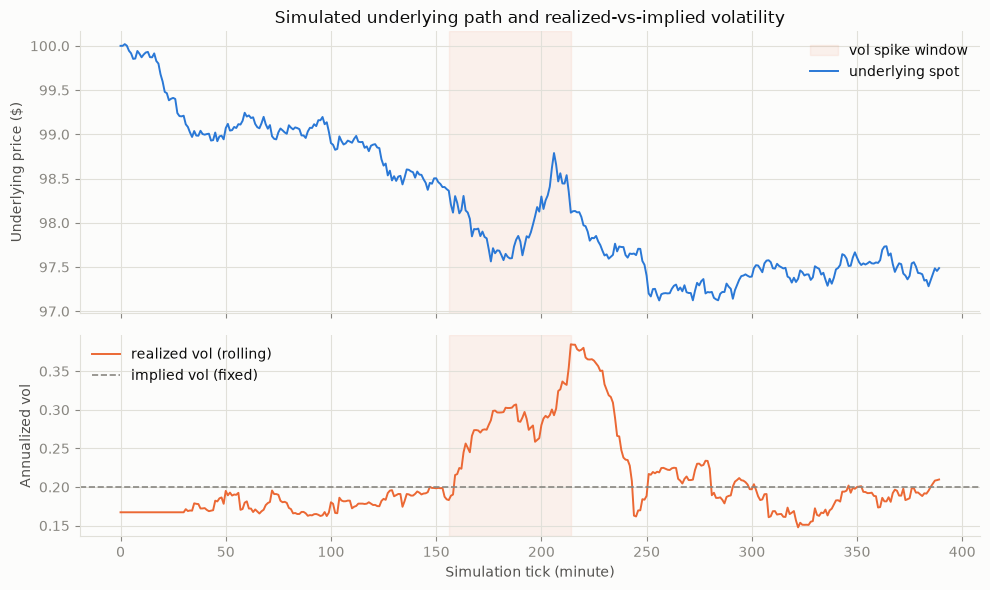

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[1.4, 1])

ax1.axvspan(spike_start, spike_end, color=ORANGE, alpha=0.08, label="vol spike window")
ax1.plot(ticks["step"], ticks["spot"], color=BLUE, linewidth=1.4, label="underlying spot")
ax1.set_ylabel("Underlying price ($)")
ax1.set_title("Simulated underlying path and realized-vs-implied volatility")
ax1.legend(loc="upper right", frameon=False)

ax2.axvspan(spike_start, spike_end, color=ORANGE, alpha=0.08)
ax2.plot(ticks["step"], ticks["realized_vol"], color=ORANGE, linewidth=1.4, label="realized vol (rolling)")
ax2.axhline(config.base_vol, color=INK_MUTED, linestyle="--", linewidth=1.2, label="implied vol (fixed)")
ax2.set_ylabel("Annualized vol")
ax2.set_xlabel("Simulation tick (minute)")
ax2.legend(loc="upper left", frameon=False)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


## 3. How the market maker sets quotes

The engine doesn't just widen a fixed spread — it builds the bid/ask as theo
plus a **sum of named, inspectable components**: a base edge floor, an
inventory term (skews the whole market when the book gets long or short, not
just widens it), a gamma term (near-the-money/near-expiry risk), a
realized-vs-implied vol mismatch term, and a toxicity term (see §5). The chart
below shows the at-the-money call's quoted market around its theoretical
value for the whole session — every widening you see below is one of those
components firing.


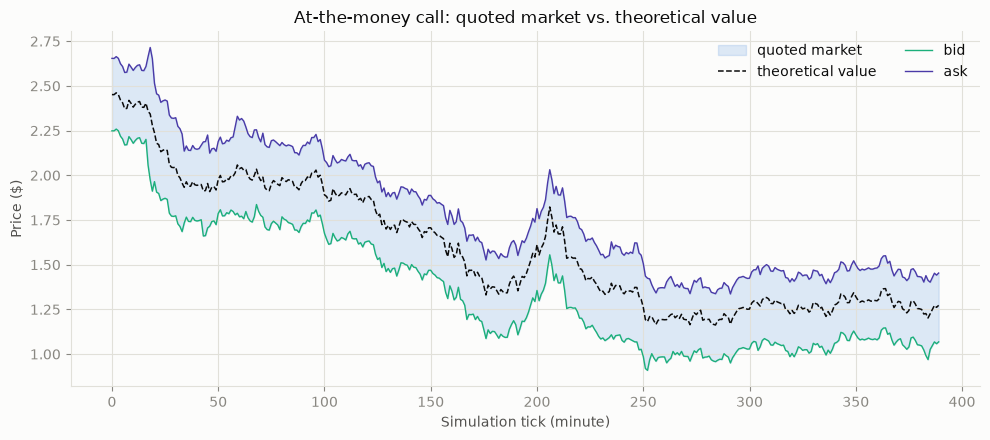

ATM half-spread ranged from $0.188 to $0.371 over the session (theo ~$1.59).


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.fill_between(ticks["step"], ticks["atm_bid"], ticks["atm_ask"], color=BLUE, alpha=0.15, label="quoted market")
ax.plot(ticks["step"], ticks["atm_theo"], color=INK, linewidth=1.1, linestyle="--", label="theoretical value")
ax.plot(ticks["step"], ticks["atm_bid"], color=AQUA, linewidth=1.0, label="bid")
ax.plot(ticks["step"], ticks["atm_ask"], color=VIOLET, linewidth=1.0, label="ask")

ax.set_title("At-the-money call: quoted market vs. theoretical value")
ax.set_xlabel("Simulation tick (minute)")
ax.set_ylabel("Price ($)")
ax.legend(loc="upper right", frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

print(f"ATM half-spread ranged from ${ticks['atm_half_spread'].min():.3f} to ${ticks['atm_half_spread'].max():.3f} "
      f"over the session (theo ~${ticks['atm_theo'].mean():.2f}).")


## 4. Managing inventory: position, delta, and hedging

Every customer fill hands the market maker some delta exposure. The hedger
watches the *net* delta — options exposure plus whatever's already been
traded in the underlying — and flattens it whenever it strays outside a
threshold band (or, as a backstop, at least every N ticks regardless). The
top panel shows that net delta staying inside its band all session; the
bottom panel shows each individual hedge trade in the underlying, colored by
which trigger fired it.


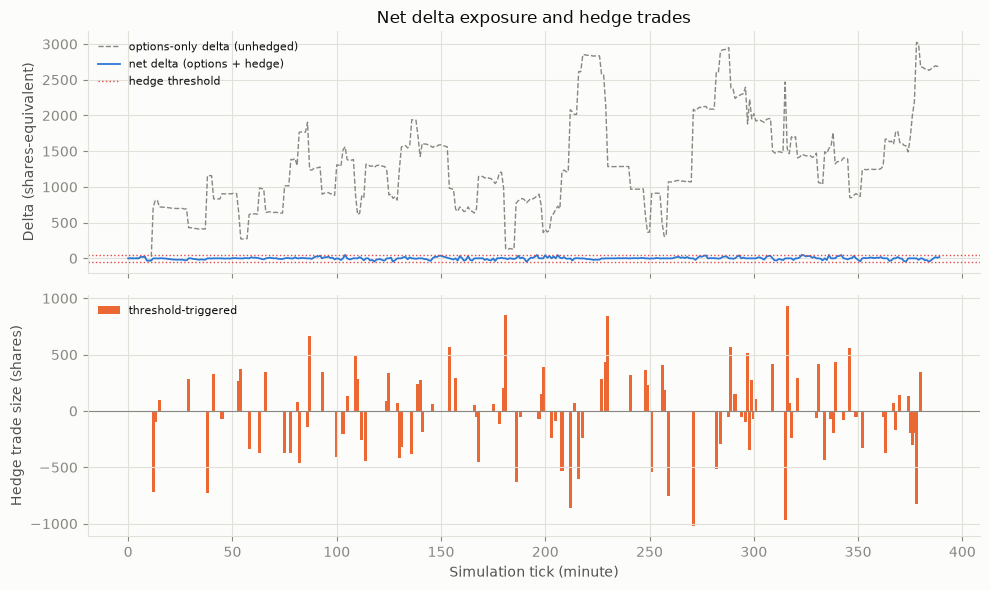

Net delta stayed within +/-49.0 shares-equivalent all session (threshold: +/-50).
Total hedging cost paid: $172.43 across 107 hedge trades.


In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[1, 1])

ax1.plot(ticks["step"], ticks["net_delta_options"], color=INK_MUTED, linewidth=1.0, linestyle="--", label="options-only delta (unhedged)")
ax1.plot(ticks["step"], ticks["net_delta_total"], color=BLUE, linewidth=1.3, label="net delta (options + hedge)")
ax1.axhline(config.hedging.delta_threshold, color=RED, linestyle=":", linewidth=1.0, label="hedge threshold")
ax1.axhline(-config.hedging.delta_threshold, color=RED, linestyle=":", linewidth=1.0)
ax1.set_ylabel("Delta (shares-equivalent)")
ax1.set_title("Net delta exposure and hedge trades")
ax1.legend(loc="upper left", frameon=False, fontsize=8)

if len(hedges):
    for reason, color, label in [("threshold", ORANGE, "threshold-triggered"), ("time", AQUA, "time-triggered"), ("risk_limit_breach", RED, "forced (risk limit)")]:
        subset = hedges[hedges["reason"] == reason]
        if len(subset):
            ax2.bar(subset["step_index"], subset["shares"], color=color, width=1.5, label=label)
ax2.axhline(0, color=INK_MUTED, linewidth=0.8)
ax2.set_ylabel("Hedge trade size (shares)")
ax2.set_xlabel("Simulation tick (minute)")
ax2.legend(loc="upper left", frameon=False, fontsize=8)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Net delta stayed within +/-{ticks['net_delta_total'].abs().max():.1f} shares-equivalent all session "
      f"(threshold: +/-{config.hedging.delta_threshold:.0f}).")
print(f"Total hedging cost paid: ${hedges['cost'].sum():.2f} across {len(hedges)} hedge trades.")


## 5. When risk limits kick in

Quoting and hedging are the soft controls. Underneath them sit hard caps on
gamma and vega exposure — if the book's dollar gamma or dollar vega crosses
its limit, new risk-increasing orders in that direction are rejected
(`lockout_new_risk`) until the book is back under the cap. A breach beyond
the limit doesn't happen here, but the mechanism is the same escalation path
that would trigger a full trading halt in a more extreme run. Notice this
isn't from the vol-spike window — it's simply the book's own inventory
building up gamma/vega risk through ordinary customer flow.


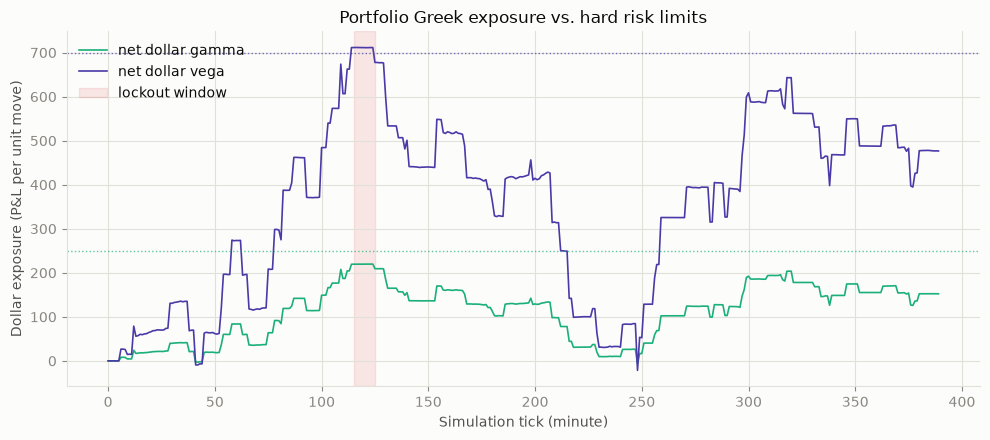

11 breach ticks, all 'lockout_new_risk' on metric 'net_vega', spanning ticks 115-125.
The book's own vega grew past the limit purely from accumulated customer flow, not from the vol regime shift.


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(ticks["step"], ticks["net_gamma_dollars"], color=AQUA, linewidth=1.2, label="net dollar gamma")
ax.plot(ticks["step"], ticks["net_vega_dollars"], color=VIOLET, linewidth=1.2, label="net dollar vega")
ax.axhline(config.risk_limits.max_net_gamma_dollars, color=AQUA, linestyle=":", linewidth=1.0, alpha=0.7)
ax.axhline(config.risk_limits.max_net_vega_dollars, color=VIOLET, linestyle=":", linewidth=1.0, alpha=0.7)

if len(breaches):
    breach_steps = breaches["step_index"]
    ax.axvspan(breach_steps.min(), breach_steps.max(), color=RED, alpha=0.12, label="lockout window")

ax.set_title("Portfolio Greek exposure vs. hard risk limits")
ax.set_xlabel("Simulation tick (minute)")
ax.set_ylabel("Dollar exposure (P&L per unit move)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

if len(breaches):
    print(f"{len(breaches)} breach ticks, all '{breaches['action'].iloc[0]}' on metric '{breaches['metric'].iloc[0]}', "
          f"spanning ticks {breaches['step_index'].min()}-{breaches['step_index'].max()}.")
    print("The book's own vega grew past the limit purely from accumulated customer flow, not from the vol regime shift.")
else:
    print("No risk limit breaches this run.")


## 6. P&L: how the money was actually made

This is the point of the whole exercise. Total P&L is decomposed into three
pieces that reconcile exactly by construction:

- **spread capture** — edge earned trading away from theo (this is the
  "reward" for making markets, and should dominate on a well-run book)
- **hedging cost** — the transaction cost paid crossing the underlying's own
  spread to stay flat (the direct cost of risk control)
- **residual risk P&L** — everything else: mark-to-market swings from
  unhedged gamma/vega/theta drift between hedges

If spread capture isn't comfortably larger than hedging cost plus the
volatility of the residual line, the desk is quoting too tight for the risk
it's taking on.


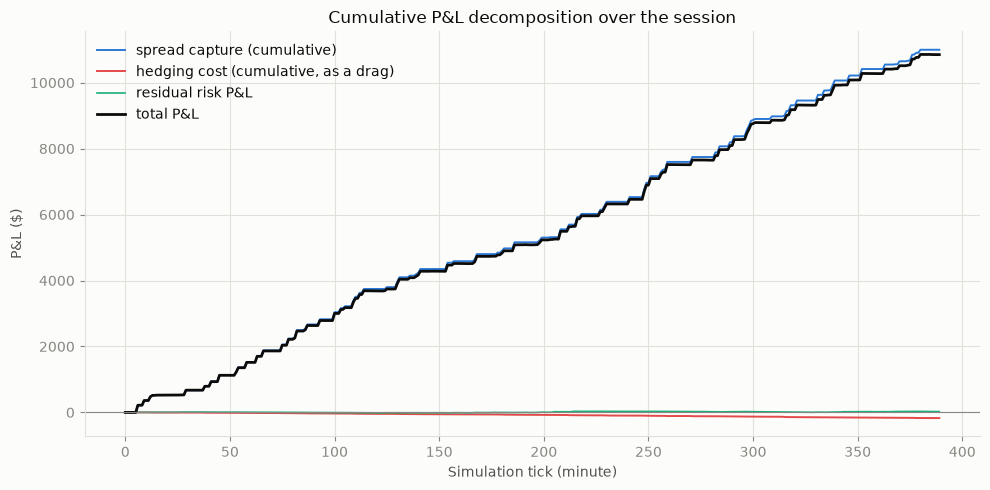

Final total P&L:        $10,849.94
  spread capture:       $10,998.18
  hedging cost:         -$172.43
  residual risk P&L:    $24.19
  (reconciles: 10,849.94)


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(ticks["step"], ticks["cumulative_spread_capture"], color=BLUE, linewidth=1.4, label="spread capture (cumulative)")
ax.plot(ticks["step"], -ticks["cumulative_hedging_cost"], color=RED, linewidth=1.4, label="hedging cost (cumulative, as a drag)")
ax.plot(ticks["step"], ticks["residual_risk_pnl"], color=AQUA, linewidth=1.2, label="residual risk P&L")
ax.plot(ticks["step"], ticks["total_pnl"], color=INK, linewidth=2.0, label="total P&L")
ax.axhline(0, color=INK_MUTED, linewidth=0.8)

ax.set_title("Cumulative P&L decomposition over the session")
ax.set_xlabel("Simulation tick (minute)")
ax.set_ylabel("P&L ($)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

final = ticks.iloc[-1]
print(f"Final total P&L:        ${final['total_pnl']:,.2f}")
print(f"  spread capture:       ${final['cumulative_spread_capture']:,.2f}")
print(f"  hedging cost:         -${final['cumulative_hedging_cost']:,.2f}")
print(f"  residual risk P&L:    ${final['residual_risk_pnl']:,.2f}")
print(f"  (reconciles: {final['cumulative_spread_capture'] - final['cumulative_hedging_cost'] + final['residual_risk_pnl']:,.2f})")


## 7. Session summary

A few numbers that round out the picture: how much flow the book actually
traded, what it earned per fill on average, and how much of the day's edge
hedging gave back.


In [8]:
avg_edge_per_fill = final["cumulative_spread_capture"] / len(fills) if len(fills) else float("nan")
hedging_drag_pct = final["cumulative_hedging_cost"] / final["cumulative_spread_capture"] * 100 if final["cumulative_spread_capture"] else float("nan")

summary = pd.Series({
    "Customer fills": len(fills),
    "Hedge trades": len(hedges),
    "Risk limit breach ticks": len(breaches),
    "Avg spread edge captured per fill ($)": avg_edge_per_fill,
    "Hedging cost as % of spread capture": hedging_drag_pct,
    "Final total P&L ($)": final["total_pnl"],
}, name="value")
summary.to_frame()


,value
Customer fills,102.00
Hedge trades,107.00
Risk limit breach ticks,11.00
Avg spread edge captured per fill ($),107.83
Hedging cost as % of spread capture,1.57
Final total P&L ($),"10,849.94"


## Takeaways

- The market maker's quotes moved for identifiable, explainable reasons —
  inventory, gamma, a real vol mismatch, and (via the toxicity signal) how its
  own recent fills have been working out — not from an opaque model.
- Delta stayed inside a tight band all session because the hedger did its job;
  the cost of that discipline shows up explicitly as the hedging-cost line.
- Gamma and vega, which the underlying-only hedge doesn't touch, drifted up
  through the session purely from absorbing customer flow, and the hard risk
  limit caught it — this is exactly the gap between "delta hedged" and
  "risk-free" that a real options desk has to manage.
- Spread capture was the dominant source of P&L, which is the sign of a
  reasonably-run book: the edge earned making markets outweighed both the
  cost of hedging and the noise from carrying risk between hedges.

**Reminder:** this is a fully simulated environment (synthetic price path,
synthetic order flow, no real execution, slippage, or market impact modeling
beyond what's described above). See the README for the full disclaimer.
